# SEÑAL · Análisis y estimación de tarifas de creadores

**Proyecto original: CreatorROI · Salvador Cruz · Ironhack Data Analytics**

## 1. Objetivo y recorrido

El proyecto ayuda a agencias y marcas a comparar creadores de Instagram del
mercado indio según su categoría, sus métricas y su presupuesto. Se exploran
los datos y se comparan modelos de regresión para estimar la tarifa de un reel.
La aplicación Streamlit presenta este trabajo bajo la marca **SEÑAL**.

### Índice

1. Objetivo y recorrido.
2. Entorno y carga de los datos.
3. Selección de Instagram y conversión a euros.
4. Análisis exploratorio.
5. Preparación de los datos para el modelo.
6. Desarrollo y evaluación de modelos.
7. Ajuste de hiperparámetros.
8. Evaluación final en prueba.
9. Guardado de los datos y del modelo.
10. Comprobación de las variables para Streamlit.
11. Conclusiones y próximos pasos.

### Cómo leer y ejecutar este notebook

Las explicaciones acompañan a las celdas y las salidas guardadas permiten revisar
el trabajo sin volver a entrenar. Para reproducirlo, se ejecutan las celdas en
orden desde la raíz de `creator-roi`, con `funciones.py` y el archivo Excel original.
El notebook también utiliza matplotlib y openpyxl, además de las dependencias de
la aplicación.

La sección de guardado escribe de nuevo el CSV preparado y el archivo del modelo.
Abrir el notebook para leerlo no modifica estos archivos.

Los resultados numéricos de los textos corresponden a las salidas conservadas.
Si se vuelve a ejecutar con otro entorno, hay que revisar su correspondencia.

## 2. Entorno y carga de los datos

### Intérprete de Python

Se comprueba qué instalación de Python utiliza el notebook. Esto ayuda a
seleccionar en VS Code el entorno donde están instaladas las librerías del proyecto.

In [130]:
import sys

print(sys.executable)

c:\Users\salde\anaconda3\python.exe


### Librerías y funciones reutilizables

Se importan las herramientas de análisis y modelado. Las funciones de
`funciones.py` permiten reutilizar la evaluación, la codificación y la predicción.
Se muestran las versiones para facilitar la reproducción del trabajo.

In [82]:
from pathlib import Path
import joblib
import numpy as np
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.model_selection import GridSearchCV
from funciones import evaluar_modelo, codificar_datos, guardar_modelo, predecir_tarifas

print("Versiones:", "sklearn", sklearn.__version__, "pandas", pd.__version__, "numpy", np.__version__)


Versiones: sklearn 1.9.0 pandas 3.0.3 numpy 2.4.6


### Archivo de origen

Se carga `data/raw/CreatorROI_Influencers_10000.xlsx` y se muestran las primeras filas.
El archivo contiene perfiles de Instagram, YouTube y Facebook.
Los precios originales están expresados en rupias indias (INR).
Primero se revisa el conjunto completo y después se selecciona Instagram.

In [83]:
creadores = pd.read_excel("data/raw/CreatorROI_Influencers_10000.xlsx")

creadores.head()

,Influencer_ID,Influencer_Name,Platform,Category,City,Language,Followers,Average_Likes,Average_Comments,Average_Shares,Average_Saves,Number_of_Posts_Analyzed,Average_Views_Per_Content,Engagement_Rate_Percent,Price_Per_Reel_INR,Price_Per_Story_INR,Available_For_Collaboration
0,INF00001,Ishita Tiwari (@theishitat),Instagram,Home Decor,Jaipur,English,30000000,599202,24785,40168,26888,30,9885030,2.08,10700000,3522500,Yes
1,INF00002,Aleena Varghese (@thealeenav_fit),YouTube,Finance,Kochi,English,30000000,541688,19612,35499,43144,41,5265183,1.87,27700000,6421000,Yes
2,INF00003,Harsha Chowdary (@harshachowdary_vlogs),Instagram,Beauty,Hyderabad,English,25233963,498538,21631,28358,32827,12,2962257,2.06,11925000,3206500,No
3,INF00004,Kritika Tiwari (@kritika.tiwari_eats),Instagram,Fashion,Delhi,Hinglish,21290128,153980,2784,3970,2079,29,4569945,0.74,4525000,1230000,No
4,INF00005,Omkar Jadhav (@omkar_jadhav_life),Instagram,Education,Pune,Marathi,19403542,416885,10257,10120,18896,13,1223436,2.20,5900000,1770500,Yes


### Tamaño y estructura del dataset

Se comprueba cuántas filas y columnas contiene el archivo, qué tipo
de datos tiene cada variable y si hay valores ausentes.

In [84]:
creadores.shape

(10000, 17)

In [85]:
creadores.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Influencer_ID                10000 non-null  str    
 1   Influencer_Name              10000 non-null  str    
 2   Platform                     10000 non-null  str    
 3   Category                     10000 non-null  str    
 4   City                         10000 non-null  str    
 5   Language                     10000 non-null  str    
 6   Followers                    10000 non-null  int64  
 7   Average_Likes                10000 non-null  int64  
 8   Average_Comments             10000 non-null  int64  
 9   Average_Shares               10000 non-null  int64  
 10  Average_Saves                10000 non-null  int64  
 11  Number_of_Posts_Analyzed     10000 non-null  int64  
 12  Average_Views_Per_Content    10000 non-null  int64  
 13  Engagement_Rate_Percent     

### Comprobación de duplicados y plataformas

Se revisa si existen filas repetidas o identificadores de creadores
duplicados. También se cuenta cuántos registros pertenecen a cada
plataforma antes de seleccionar Instagram.

In [86]:
creadores.duplicated().sum()

np.int64(0)

In [87]:
creadores["Influencer_ID"].duplicated().sum()

np.int64(0)

In [88]:
creadores["Platform"].value_counts()

Platform
Instagram    7800
YouTube      1544
Facebook      656
Name: count, dtype: int64

## 3. Selección de Instagram y conversión a euros

El proyecto se centra en estimar el precio de un reel en Instagram.
Se seleccionan los perfiles de esta plataforma para comparar creadores
dentro de un mismo contexto.

Se crea una copia para conservar intactos los datos originales.

In [89]:
instagram = creadores[creadores["Platform"] == "Instagram"].copy()

instagram.shape

(7800, 17)

### Conversión de las tarifas a euros

Se conservan los precios originales en rupias indias y se añaden
columnas en euros para facilitar la interpretación.

Se utiliza un cambio fijo de referencia del Banco Central Europeo:
1 EUR = 106,0395 INR, correspondiente al 5 de noviembre de 2026.

Esta conversión permite comparar los importes en una moneda familiar.
Las tarifas siguen correspondiendo al mercado indio.

Fuente: https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html

In [90]:
inr_por_euro = 106.0395

instagram["Price_Per_Reel_EUR"] = (
    instagram["Price_Per_Reel_INR"] / inr_por_euro
)

instagram["Price_Per_Story_EUR"] = (
    instagram["Price_Per_Story_INR"] / inr_por_euro
)

instagram[[
    "Price_Per_Reel_INR",
    "Price_Per_Reel_EUR",
    "Price_Per_Story_INR",
    "Price_Per_Story_EUR"
]].head().round(2)

,Price_Per_Reel_INR,Price_Per_Reel_EUR,Price_Per_Story_INR,Price_Per_Story_EUR
0,10700000,100905.79,3522500,33218.75
2,11925000,112458.09,3206500,30238.73
3,4525000,42672.78,1230000,11599.45
4,5900000,55639.64,1770500,16696.61
5,7200000,67899.23,2201000,20756.42


## 4. Análisis exploratorio

### Resumen de las variables numéricas

Se revisan los valores mínimos, máximos, la media y la mediana de las
métricas y las tarifas. Esto permite conocer las diferencias entre
perfiles y detectar valores que convenga revisar.

Los precios de este resumen están expresados en euros (€).

In [91]:
instagram.drop(columns=[
    "Price_Per_Reel_INR",
    "Price_Per_Story_INR"
]).describe().round(2)

,Followers,Average_Likes,Average_Comments,Average_Shares,Average_Saves,Number_of_Posts_Analyzed,Average_Views_Per_Content,Engagement_Rate_Percent,Price_Per_Reel_EUR,Price_Per_Story_EUR
count,7800.00,7800.00,7800.00,7800.00,7800.00,7800.00,7800.00,7800.00,7800.00,7800.00
mean,263459.13,4464.13,166.62,223.18,171.37,31.14,76078.83,4.09,1204.86,414.12
std,965481.09,16533.01,654.86,894.72,734.59,11.29,243621.01,2.73,3753.48,1248.51
min,1001.00,8.00,0.00,0.00,0.00,12.00,92.00,0.17,14.15,4.72
25%,4490.50,211.00,10.00,10.00,7.00,21.00,3533.00,2.14,42.44,14.15
50%,20997.00,673.50,27.00,32.00,24.00,31.00,11524.00,3.47,150.89,51.87
75%,103323.25,2879.00,100.00,141.00,98.00,41.00,49872.75,5.35,660.13,231.05
max,30000000.00,599202.00,24785.00,40168.00,32827.00,50.00,9885030.00,25.01,112458.09,33218.75


### Primeras observaciones

La mediana del precio por reel es de aproximadamente 151 €,
mientras que la media ronda los 1.205 €. Las tarifas más elevadas
aumentan considerablemente el promedio.

Se conservan los perfiles con precios extremos cuando no existe
evidencia de un error.

In [92]:
instagram.sort_values(
    "Price_Per_Reel_EUR",
    ascending=False
)[[
    "Influencer_Name",
    "Category",
    "Followers",
    "Average_Views_Per_Content",
    "Engagement_Rate_Percent",
    "Price_Per_Reel_EUR"
]].head(10).round(2)

,Influencer_Name,Category,Followers,Average_Views_Per_Content,Engagement_Rate_Percent,Price_Per_Reel_EUR
2,Harsha Chowdary (@harshachowdary_vlogs),Beauty,25233963,2962257,2.06,112458.09
0,Ishita Tiwari (@theishitat),Home Decor,30000000,9885030,2.08,100905.79
5,Aarav Tiwari (@aaravtiwari),Tech,17179998,4697319,2.44,67899.23
6,Rakesh Bhat (@rakesh_bhat_eats),Tech,16738145,3510885,2.32,66956.18
4,Omkar Jadhav (@omkar_jadhav_life),Education,19403542,1223436,2.20,55639.64
18,Kiran Hegde (@thekiranh_tech),Beauty,9091769,1800836,1.30,54696.60
3,Kritika Tiwari (@kritika.tiwari_eats),Fashion,21290128,4569945,0.74,42672.78
60,Anushka Pawar (@anushka_pawar_creates),Beauty,4902333,914076,1.41,40079.40
48,Aniket Joshi (@aniket.joshi_x),Finance,5369008,1122764,2.15,38193.31
17,Aishwarya Joshi (@aishwaryajoshi_life),Finance,9149031,3095327,1.23,35599.94


### Interpretación de las diferencias de precio

Las tarifas de los influencers no dependen únicamente de sus seguidores
o visualizaciones. También pueden influir la calidad del contenido,
la notoriedad del creador, su audiencia y las condiciones de colaboración.

El dataset no recoge todos estos factores. Incluye la ciudad del creador,
pero no la ubicación ni las características de su audiencia.

Por este motivo, se conservan los perfiles con tarifas extremas cuando
no existe evidencia de un error. El modelo ofrecerá una estimación
basada en las variables disponibles, no un precio correcto o definitivo.

### Distribución por categoría

Se cuenta cuántos creadores hay en cada categoría para conocer
la composición del dataset y detectar categorías poco representadas.

In [93]:
instagram["Category"].value_counts()

Category
Fashion          849
Beauty           837
Lifestyle        809
Food             759
Fitness          640
Travel           566
Comedy           545
Tech             527
Finance          487
Education        439
Parenting        425
Gaming           343
Music & Dance    236
Home Decor       231
Auto             107
Name: count, dtype: int64

### Número de creadores por categoría

Fashion, Beauty y Lifestyle son las categorías con más perfiles.
Auto es la menos representada.

El gráfico muestra la composición del dataset. Estas cantidades no
representan necesariamente la distribución del mercado de influencers.

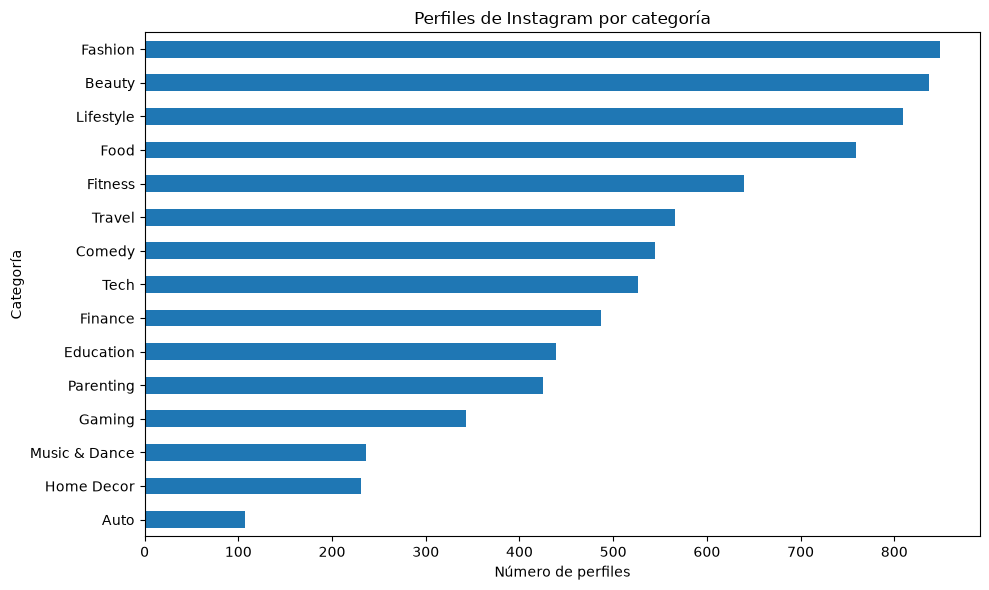

In [94]:
instagram["Category"].value_counts().sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Perfiles de Instagram por categoría")
plt.xlabel("Número de perfiles")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

### Precio mediano por reel según la categoría

Se calcula la mediana del precio por categoría para comparar las
tarifas centrales sin que los valores más elevados dominen el resultado.

Las diferencias también pueden estar relacionadas con el tamaño y las
características de los perfiles. No se atribuyen únicamente a la categoría.
Los precios están expresados en euros (€).

In [95]:
precio_por_categoria = instagram.groupby(
    "Category"
)["Price_Per_Reel_EUR"].median().sort_values(ascending=False)

precio_por_categoria.round(2)

Category
Lifestyle        216.90
Fashion          188.61
Finance          183.89
Beauty           165.03
Tech             155.60
Education        146.17
Food             146.17
Parenting        141.46
Home Decor       136.74
Auto             136.74
Comedy           132.03
Fitness          132.03
Travel           122.60
Music & Dance    117.88
Gaming            89.59
Name: Price_Per_Reel_EUR, dtype: float64

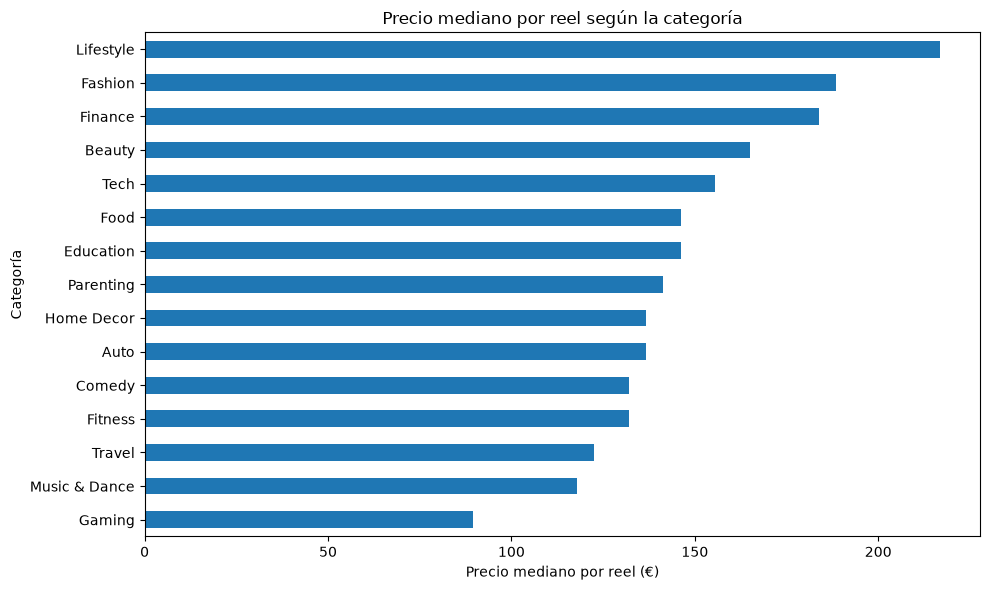

In [96]:
precio_por_categoria.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Precio mediano por reel según la categoría")
plt.xlabel("Precio mediano por reel (€)")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

Lifestyle presenta el precio mediano más alto, con unos 217 € por reel,
y Gaming el más bajo, con unos 90 €.

Estas diferencias describen los perfiles del dataset. No demuestran
que la categoría sea la causa de una tarifa mayor o menor.

### Audiencia y precio por categoría

Se comparan los seguidores medianos y el precio mediano por reel
de cada categoría. Esto permite observar si las categorías con tarifas
más altas también agrupan perfiles con audiencias más grandes.

Esta comparación es descriptiva y no demuestra que una variable
sea la causa de la otra.

In [97]:
resumen_categorias = instagram.groupby("Category")[[
    "Followers",
    "Price_Per_Reel_EUR"
]].median().sort_values(
    "Price_Per_Reel_EUR",
    ascending=False
)

resumen_categorias.round(2)

,Followers,Price_Per_Reel_EUR
Category,,
Lifestyle,24945.0,216.90
Fashion,20448.0,188.61
Finance,17280.0,183.89
Beauty,18741.0,165.03
Tech,20164.0,155.60
Education,21661.0,146.17
Food,22474.0,146.17
Parenting,21738.0,141.46
Home Decor,21074.0,136.74


Finance y Gaming tienen un número mediano de seguidores similar,
pero sus tarifas medianas son de aproximadamente 184 € y 90 €,
respectivamente.

Esto refuerza la necesidad de estudiar otras características además
del número de seguidores.

### Relación entre seguidores y precio por reel

Cada punto representa un creador. Primero se observa la relación en escala
lineal; después se utiliza una escala logarítmica para distinguir los perfiles
con tamaños y tarifas muy diferentes.

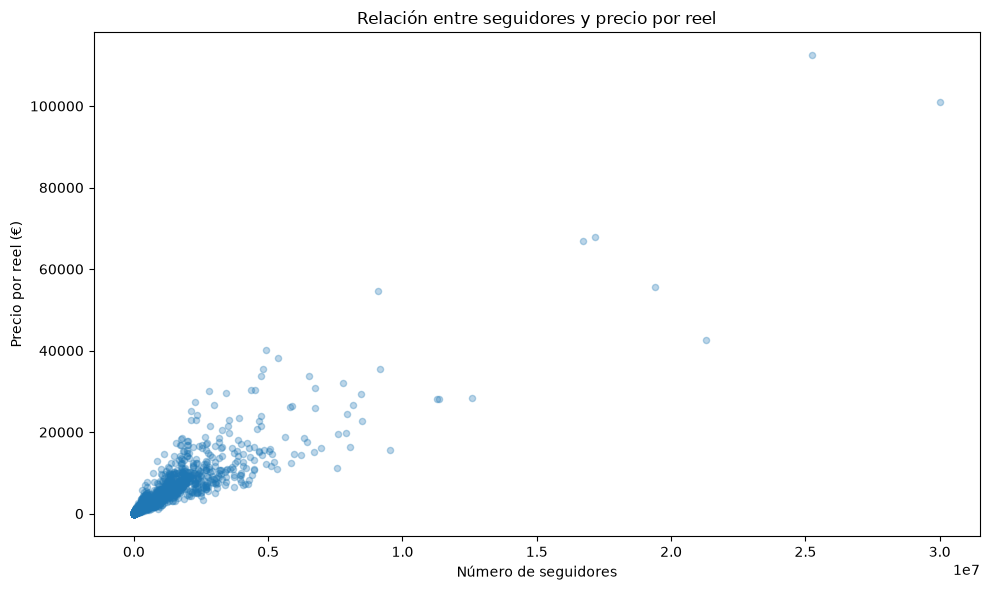

In [98]:
instagram.plot(
    kind="scatter",
    x="Followers",
    y="Price_Per_Reel_EUR",
    figsize=(10, 6),
    alpha=0.3
)

plt.title("Relación entre seguidores y precio por reel")
plt.xlabel("Número de seguidores")
plt.ylabel("Precio por reel (€)")
plt.tight_layout()
plt.show()

### Seguidores y tarifas en escala logarítmica

Se cambia la escala del gráfico para visualizar mejor perfiles con
tamaños muy diferentes. Cada salto principal del eje representa
multiplicar por diez.

Este ajuste solo cambia la visualización: no modifica los datos
ni elimina perfiles.

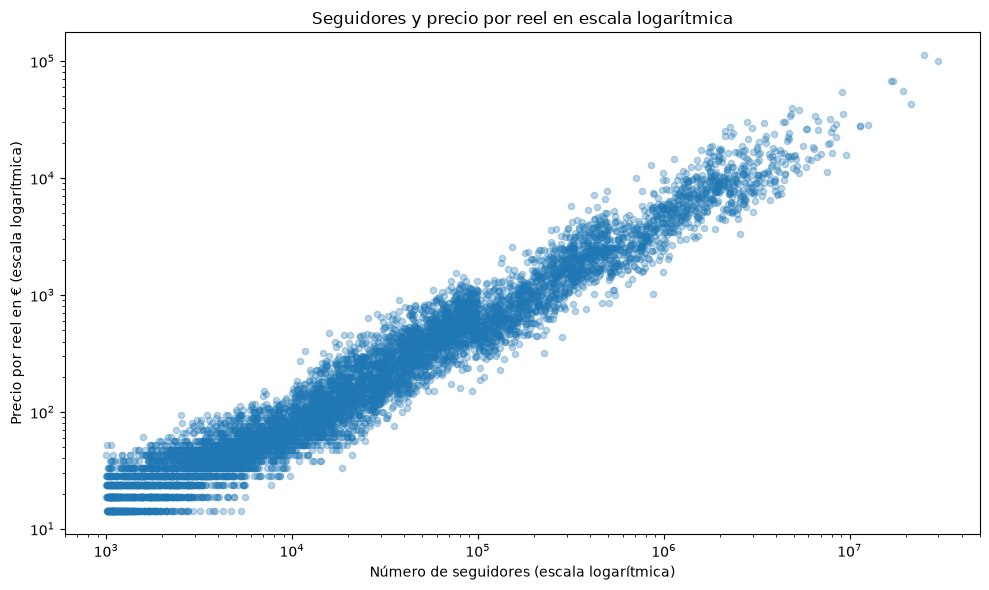

In [99]:
instagram.plot(
    kind="scatter",
    x="Followers",
    y="Price_Per_Reel_EUR",
    figsize=(10, 6),
    alpha=0.3,
    logx=True,
    logy=True
)

plt.title("Seguidores y precio por reel en escala logarítmica")
plt.xlabel("Número de seguidores (escala logarítmica)")
plt.ylabel("Precio por reel en € (escala logarítmica)")
plt.tight_layout()
plt.show()

La escala logarítmica permite observar una relación positiva entre
seguidores y precio por reel en el dataset.

También existe variación de tarifas entre perfiles con audiencias
similares. Por ello, se estudiarán otras características además
del número de seguidores.

En los precios bajos aparecen franjas horizontales que corresponden
a tarifas repetidas. Se revisarán sus frecuencias para entender
mejor la distribución.

### Tarifas que se repiten

Se cuentan las tarifas más frecuentes para entender las franjas del gráfico.
Una tarifa repetida no implica que dos registros sean duplicados.

In [100]:
instagram["Price_Per_Reel_EUR"].value_counts().head(10).rename_axis(
    "Precio por reel (€)"
).reset_index(name="Número de perfiles").round(2)

,Precio por reel (€),Número de perfiles
0,28.29,371
1,23.58,326
2,18.86,293
3,33.01,280
4,42.44,240
5,37.72,239
6,47.15,219
7,14.15,204
8,51.87,198
9,56.58,161


Las diez tarifas más frecuentes están entre aproximadamente 14 € y 57 €.
En la moneda original son múltiplos de 500 INR, lo que explica las
franjas horizontales del gráfico.

La conversión a euros produce importes con decimales. Compartir
una tarifa no significa que los perfiles estén duplicados.

### Relación entre las variables numéricas y el precio

Se calcula la correlación para explorar qué variables presentan
una relación lineal con el precio por reel.

Una correlación cercana a 1 indica que ambas variables tienden
a aumentar juntas. No demuestra causalidad ni determina por sí sola
qué variables debe utilizar el modelo.

In [101]:
instagram.drop(columns=[
    "Price_Per_Reel_EUR",
    "Price_Per_Story_EUR"
]).corr(numeric_only=True)["Price_Per_Reel_INR"].sort_values(
    ascending=False
)

Price_Per_Reel_INR           1.000000
Price_Per_Story_INR          0.984696
Followers                    0.920578
Average_Likes                0.875759
Average_Comments             0.843680
Average_Shares               0.842599
Average_Saves                0.817075
Average_Views_Per_Content    0.805976
Number_of_Posts_Analyzed    -0.026404
Engagement_Rate_Percent     -0.245071
Name: Price_Per_Reel_INR, dtype: float64

### Interpretación de las correlaciones

Los seguidores y las métricas de interacción presentan una relación
positiva con el precio por reel.

El precio por story está muy relacionado con el precio por reel,
pero se excluirá del modelo inicial para estimar tarifas utilizando
características del creador.

El engagement presenta una correlación negativa débil. Esta relación
no demuestra causalidad y debe interpretarse teniendo en cuenta
el tamaño de los perfiles.

No se eliminarán variables únicamente por tener una correlación baja:
podrían aportar información al combinarse con otras.

In [102]:
instagram[[
    "Followers",
    "Engagement_Rate_Percent",
    "Price_Per_Reel_INR"
]].corr()

,Followers,Engagement_Rate_Percent,Price_Per_Reel_INR
Followers,1.000000,-0.233101,0.920578
Engagement_Rate_Percent,-0.233101,1.000000,-0.245071
Price_Per_Reel_INR,0.920578,-0.245071,1.000000


Los seguidores presentan una correlación positiva fuerte con el precio
y una correlación negativa débil con la tasa de engagement.

Estas relaciones sugieren que el tamaño del perfil debe tenerse
en cuenta al interpretar el engagement. No demuestran que aumentar
el engagement provoque una reducción del precio.

### Perfiles y tarifas por ciudad

Se revisan las ciudades con más perfiles y su precio mediano por reel.
También se incluyen los seguidores medianos para contextualizar
las diferencias.

La ciudad corresponde al creador, no a la ubicación de su audiencia.

In [103]:
resumen_ciudades = instagram.groupby("City").agg({
    "Influencer_ID": "count",
    "Followers": "median",
    "Price_Per_Reel_EUR": "median"
}).sort_values(
    "Influencer_ID",
    ascending=False
)

resumen_ciudades.head(10).round(2)

,Influencer_ID,Followers,Price_Per_Reel_EUR
City,,,
Mumbai,1014,22810.5,165.03
Delhi,890,25517.5,198.04
Bengaluru,708,19402.0,141.46
Hyderabad,484,15973.0,110.81
Chennai,433,19695.0,132.03
Pune,383,21824.0,155.60
Kolkata,377,17922.0,122.60
Ahmedabad,301,22368.0,160.32
Jaipur,256,29335.0,212.19


Entre las diez ciudades con más perfiles, Jaipur presenta la tarifa
mediana más alta, con unos 212 €, e Hyderabad la más baja, con unos 111 €.

También existen diferencias en el tamaño de sus audiencias.
Por tanto, no se atribuyen estas diferencias únicamente a la ciudad.

### Tratamiento de la disponibilidad

La disponibilidad para colaborar no se utilizará como filtro ni
como variable del modelo. Se incluirán todos los perfiles de Instagram
en el análisis.

En un uso real, la disponibilidad se confirmaría directamente con
el creador antes de contratar una colaboración.

## 5. Preparación de los datos para el modelo

El objetivo es estimar el precio de un reel en euros a partir de
las características del creador.

Se separan los datos en:
- X: características que utilizará el modelo para estimar el precio.
- y: precio por reel en euros que queremos predecir.

Se excluyen los nombres e identificadores, porque identifican al
creador. También se excluyen la plataforma, ya que todos los perfiles
son de Instagram, y la disponibilidad, que queda fuera del alcance.

Los precios por story y por reel, tanto en rupias como en euros,
no se incluyen en X. Así, el modelo estima la tarifa utilizando
las características del perfil, sin recibir otros precios como entrada.

Se conservan los importes originales en el dataset.
Las predicciones y los errores se expresarán en euros.

In [104]:
X = instagram.drop(columns=[
    "Influencer_ID",
    "Influencer_Name",
    "Platform",
    "Available_For_Collaboration",
    "Price_Per_Story_INR",
    "Price_Per_Reel_INR",
    "Price_Per_Reel_EUR",
    "Price_Per_Story_EUR"
])

y = instagram["Price_Per_Reel_EUR"]

X.shape, y.shape

((7800, 11), (7800,))

### División en entrenamiento, validación y prueba

Los datos se separan en tres grupos:

- Entrenamiento (60 %): permite que los modelos aprendan.
- Validación (20 %): sirve para comparar modelos y ajustar sus parámetros.
- Prueba (20 %): se reserva para evaluar el modelo elegido al final.

La división se realiza antes de ajustar las transformaciones de los
datos. Se fija random_state para obtener la misma división al ejecutar
de nuevo el notebook.

In [105]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42
)

X_train.shape, X_val.shape, X_test.shape

((4680, 11), (1560, 11), (1560, 11))

### Conversión de variables categóricas

Categoría, ciudad e idioma se convierten en columnas numéricas con get_dummies.
Las categorías y el orden de columnas se fijan usando el entrenamiento.
Así una columna conserva el mismo significado al comparar modelos y al introducir
un nuevo perfil en la futura aplicación. Las categorías desconocidas se avisan.
La función que realiza este paso está en funciones.py.


In [106]:
columnas_categoricas = ["Category", "City", "Language"]
# Se fija el mismo significado para cada columna en todos los conjuntos.
categorias = {
    columna: sorted(X_train[columna].unique().tolist())
    for columna in columnas_categoricas
}
X_train_encoded = codificar_datos(X_train, categorias)
columnas_modelo = X_train_encoded.columns.tolist()
X_val_encoded = codificar_datos(X_val, categorias, columnas_modelo)
X_test_encoded = codificar_datos(X_test, categorias, columnas_modelo)
X_train_encoded.shape, X_val_encoded.shape, X_test_encoded.shape


((4680, 72), (1560, 72), (1560, 72))

### Escalado de las variables

Se utiliza MinMaxScaler para llevar las variables de entrenamiento
a una escala entre 0 y 1.

El escalador aprende los mínimos y máximos únicamente del entrenamiento.
Después aplica esa misma transformación a validación y prueba.

En validación y prueba pueden aparecer valores fuera del intervalo
si superan los límites observados en entrenamiento. Esto no es un error.

El precio objetivo se mantiene en euros, sin escalar.

In [107]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)

X_val_scaled = scaler.transform(X_val_encoded)

X_test_scaled = scaler.transform(X_test_encoded)

X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape

((4680, 72), (1560, 72), (1560, 72))

## 6. Desarrollo y evaluación de modelos

### Modelo de referencia

Como punto de partida, se utiliza el precio mediano del entrenamiento
como predicción para todos los perfiles de validación.

Se calcula el error absoluto medio (MAE), que indica cuántos euros
se desvía la predicción del precio registrado, de media y sin considerar
el signo del error.

Cuanto menor sea el MAE, mejor será el resultado según esta métrica.
Los modelos se compararán con esta referencia.
El conjunto de prueba permanece reservado para la evaluación final.
La función evaluar_modelo reúne el entrenamiento y el cálculo de errores para evitar repetir el mismo bloque. Cada modelo conserva su celda y explicación.


In [108]:
precio_referencia = y_train.median()

predicciones_referencia = [
    precio_referencia
] * len(y_val)

mae_referencia = mean_absolute_error(
    y_val,
    predicciones_referencia
)

print("Precio de referencia:", round(precio_referencia, 2), "€")
print("MAE de referencia:", round(mae_referencia, 2), "€")

Precio de referencia: 150.89 €
MAE de referencia: 1046.43 €


La predicción de referencia es de 150,89 € para todos los perfiles.
Su error absoluto medio en validación es de 1.046,43 €.

Este resultado será el punto de comparación para comprobar si
las características de los creadores permiten mejorar las estimaciones.

### Regresión lineal

La regresión lineal combina las características del creador para
estimar el precio por reel.

El modelo aprende con los datos de entrenamiento y se evalúa
con los perfiles de validación, que no ha utilizado para aprender.
Su MAE se compara con el de la referencia.

In [109]:
modelo_lineal = LinearRegression()

predicciones_lineal, mae_lineal_train, mae_lineal = evaluar_modelo(
    modelo_lineal, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 496.6 €
MAE de validación: 490.52 €
Predicciones negativas: 258


La regresión lineal obtiene un MAE de 490,52 €, frente a los
1.046,43 € de la referencia. Esto supone una reducción del error
de aproximadamente el 53,1 %.

Sin embargo, genera 258 predicciones negativas, un 16,5 % del
conjunto de validación. Estos precios no tienen sentido comercial.

Se conserva este resultado para comparar con otros modelos.
No se modifican las predicciones para ocultar esta limitación.

### Árbol de decisión

El árbol aprende reglas que dividen los perfiles en grupos según
sus características y estima un precio para cada grupo.

Puede captar relaciones que la regresión lineal no representa bien.
Se comparará su error en entrenamiento y validación para comprobar
si aprende patrones útiles o se ajusta demasiado a los datos conocidos.

In [110]:
modelo_arbol = DecisionTreeRegressor(random_state=42)

predicciones_arbol, mae_arbol_train, mae_arbol = evaluar_modelo(
    modelo_arbol, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 0.0 €
MAE de validación: 396.31 €
Predicciones negativas: 0


El árbol de decisión obtiene un MAE de 396,31 € en validación
y no genera precios negativos.

El error de entrenamiento es de 0 €, lo que muestra un ajuste
exacto a los datos conocidos. La diferencia con validación indica
sobreajuste y justifica probar límites a la complejidad del árbol.

Por ahora, mejora a la regresión lineal según el MAE de validación.

### Random Forest

Random Forest combina varios árboles entrenados con distintas
muestras y selecciones de variables.

Al promediar sus predicciones, puede reducir la variabilidad de
un árbol individual. Se comprobará si mejora el MAE de validación.

In [111]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

predicciones_rf, mae_rf_train, mae_rf = evaluar_modelo(
    modelo_rf, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 132.08 €
MAE de validación: 297.17 €
Predicciones negativas: 0


Random Forest obtiene un MAE de 297,17 € en validación y no genera
precios negativos. Es el mejor resultado entre los modelos probados
hasta este momento.

El MAE de entrenamiento es de 132,08 €. La diferencia con validación
indica que el modelo funciona mejor con los datos conocidos.

Más adelante se revisará el error según el tamaño y la tarifa de
los perfiles, porque el promedio puede ocultar diferencias importantes.

### KNN para regresión

KNN estima la tarifa de un perfil utilizando los precios de los
cinco perfiles más cercanos del entrenamiento.

Se utilizan las variables escaladas, ya que el modelo calcula
distancias entre perfiles. Se evaluará si este enfoque mejora
los resultados anteriores.

In [112]:
modelo_knn = KNeighborsRegressor(n_neighbors=5)

predicciones_knn, mae_knn_train, mae_knn = evaluar_modelo(
    modelo_knn, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 1169.21 €
MAE de validación: 1395.01 €
Predicciones negativas: 0


KNN obtiene un MAE de 1.395,01 € en validación, superior al de
la referencia. Aunque no genera precios negativos, esta configuración
no aporta una mejora.

La cercanía entre perfiles según las variables utilizadas no garantiza
que tengan tarifas similares. El resultado se conserva en la comparación.

### Bagging

Bagging entrena varios árboles con muestras aleatorias del conjunto
de entrenamiento y promedia sus predicciones.

Las muestras se extraen con reemplazo: un mismo perfil puede aparecer
varias veces en la muestra utilizada por un árbol.

Se comprobará si esta combinación mejora la estimación de tarifas.

In [113]:
modelo_bagging = BaggingRegressor(
    n_estimators=100,
    bootstrap=True,
    random_state=42
)

predicciones_bagging, mae_bagging_train, mae_bagging = evaluar_modelo(
    modelo_bagging, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 132.11 €
MAE de validación: 296.32 €
Predicciones negativas: 0


Bagging obtiene un MAE de 296,32 € en validación y de 132,11 €
en entrenamiento. No genera predicciones negativas.

Su resultado es muy similar al de Random Forest, cuyo MAE de
validación es de 297,17 €. Se mantendrán ambos como candidatos
para las siguientes comparaciones.

### Pasting

Pasting combina árboles entrenados con muestras aleatorias sin
reemplazo y promedia sus predicciones.

Cada árbol utilizará el 80 % de los perfiles de entrenamiento.
Así se generan muestras diferentes para los distintos árboles.

In [114]:
modelo_pasting = BaggingRegressor(
    n_estimators=100,
    bootstrap=False,
    max_samples=0.8,
    random_state=42
)

predicciones_pasting, mae_pasting_train, mae_pasting = evaluar_modelo(
    modelo_pasting, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 76.51 €
MAE de validación: 306.67 €
Predicciones negativas: 0


Pasting obtiene un MAE de 76,51 € en entrenamiento y de 306,67 €
en validación. No genera precios negativos.

Su menor error de entrenamiento no se traduce en una mejora frente
a Bagging en validación. Esto muestra por qué los modelos se comparan
con datos que no han utilizado para aprender.

### Gradient Boosting

Gradient Boosting construye árboles de forma secuencial.
Cada nuevo árbol intenta corregir parte de los errores de los anteriores.

Se comparará su MAE con los resultados obtenidos hasta ahora.

In [115]:
modelo_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

predicciones_gb, mae_gb_train, mae_gb = evaluar_modelo(
    modelo_gb, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 223.75 €
MAE de validación: 315.85 €
Predicciones negativas: 2


Gradient Boosting obtiene un MAE de 223,75 € en entrenamiento
y de 315,85 € en validación.

Genera dos predicciones negativas, que no tienen sentido comercial.
En esta configuración no mejora el resultado de Bagging.

Se conservan las predicciones originales para comparar los modelos
sin ocultar sus limitaciones.

### AdaBoost

AdaBoost combina varios modelos entrenados de forma secuencial.
Durante el entrenamiento, da más importancia a los perfiles que
los modelos anteriores han estimado con mayor error.

Se comprobará si este enfoque mejora la estimación de las tarifas.

In [116]:
modelo_ada = AdaBoostRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

predicciones_ada, mae_ada_train, mae_ada = evaluar_modelo(
    modelo_ada, X_train_scaled, y_train, X_val_scaled, y_val
)


MAE de entrenamiento: 487.13 €
MAE de validación: 486.42 €
Predicciones negativas: 0


AdaBoost obtiene un MAE de 487,13 € en entrenamiento y de 486,42 €
en validación. No genera predicciones negativas.

Aunque los errores son similares entre ambos conjuntos, su MAE
de validación es mayor que el de otros modelos probados.

### Comparación inicial de modelos

Los modelos se ordenan por su MAE de validación.
Un valor menor indica una menor desviación media respecto a las
tarifas registradas.

Esta comparación corresponde a las configuraciones iniciales.
Todavía no se ha realizado el ajuste de hiperparámetros ni se ha
utilizado el conjunto de prueba.

In [117]:
resultados = pd.DataFrame({
    "Modelo": [
        "Referencia",
        "Regresión lineal",
        "Árbol de decisión",
        "Random Forest",
        "KNN",
        "Bagging",
        "Pasting",
        "Gradient Boosting",
        "AdaBoost"
    ],
    "MAE validación (€)": [
        mae_referencia,
        mae_lineal,
        mae_arbol,
        mae_rf,
        mae_knn,
        mae_bagging,
        mae_pasting,
        mae_gb,
        mae_ada
    ]
})

resultados = resultados.sort_values("MAE validación (€)")

resultados.round(2)

,Modelo,MAE validación (€)
5,Bagging,296.32
3,Random Forest,297.17
6,Pasting,306.67
7,Gradient Boosting,315.85
2,Árbol de decisión,396.31
8,AdaBoost,486.42
1,Regresión lineal,490.52
0,Referencia,1046.43
4,KNN,1395.01


### Revisión de los errores de Bagging

Bagging obtiene el menor MAE de validación en la comparación inicial.
Se revisan sus predicciones para identificar los mayores errores.

El error absoluto es la diferencia entre el precio registrado y
el estimado, sin considerar el signo. Las diferencias pueden reflejar
limitaciones del modelo y características que el dataset no recoge.

In [118]:
revision_bagging = instagram.loc[X_val.index, [
    "Influencer_Name",
    "Category",
    "Followers"
]].copy()

revision_bagging["Precio registrado (€)"] = y_val
revision_bagging["Precio estimado (€)"] = predicciones_bagging

revision_bagging["Error absoluto (€)"] = (
    revision_bagging["Precio registrado (€)"]
    - revision_bagging["Precio estimado (€)"]
).abs()

revision_bagging.sort_values(
    "Error absoluto (€)",
    ascending=False
).head(10).round(2)

,Influencer_Name,Category,Followers,Precio registrado (€),Precio estimado (€),Error absoluto (€)
32,Pooja Tiwari (@pooja.tiwari_vlogs),Education,6974003,15984.61,31592.00,15607.39
119,Gauri Deshmukh (@gauri_deshmukh),Beauty,3527676,22868.84,8736.84,14132.00
37,Parth Trivedi (@parth_trivedi_vlogs),Lifestyle,6520113,33713.85,20192.95,13520.90
302,Preethi Krishnan (@thepreethik_eats),Fashion,2121897,22868.84,10234.87,12633.97
80,Rohit Patil (@rohit.patil_fit),Finance,4366693,30413.20,17930.58,12482.61
48,Aniket Joshi (@aniket.joshi_x),Finance,5369008,38193.31,29420.64,8772.67
143,Ritika Dutta (@ritika_dutta_talks),Beauty,3165191,17682.09,9539.84,8142.25
319,Sahithi Reddy (@sahithi_reddy772),Beauty,2028022,16880.50,8942.89,7937.61
390,Shruti Siddiqui (@shruti.siddiqui_x),Home Decor,1810105,18672.29,10759.20,7913.09
187,Prajakta Jadhav (@theprajaktaj_diaries),Fashion,2733757,17399.18,11196.30,6202.88


Los diez mayores errores absolutos de Bagging aparecen en perfiles
con más de un millón de seguidores y tarifas elevadas.

El modelo sobreestima algunos precios y subestima otros. Estos
registros se conservan: un error de predicción elevado no implica
un error en los datos.

Se revisará el error por tamaño de audiencia para comprobar cómo
funciona el modelo en distintos grupos de perfiles.

### Error de validación por grupo de seguidores

Se agrupan las predicciones del Bagging inicial por tamaño de perfil y se
comparan el número de casos, el precio mediano y los errores absolutos.
Este análisis corresponde al modelo inicial en validación, no al modelo final en prueba.

In [119]:
revision_bagging["Grupo de seguidores"] = pd.cut(
    revision_bagging["Followers"],
    bins=[0, 100000, 1000000, float("inf")],
    labels=[
        "Hasta 100.000",
        "Más de 100.000 hasta 1 millón",
        "Más de 1 millón"
    ]
)

errores_por_grupo = revision_bagging.groupby(
    "Grupo de seguidores",
    observed=True
).agg({
    "Followers": "count",
    "Precio registrado (€)": "median",
    "Error absoluto (€)": ["mean", "median"]
})

errores_por_grupo.round(2)

Followers Precio registrado (€)  \
                                  count                median   
Grupo de seguidores                                             
Hasta 100.000                      1188                 70.73   
Más de 100.000 hasta 1 millón       270               1376.85   
Más de 1 millón                     102               8204.49   

                              Error absoluto (€)           
                                            mean   median  
Grupo de seguidores                                        
Hasta 100.000                              44.72    15.73  
Más de 100.000 hasta 1 millón             429.02   260.04  
Más de 1 millón                          2875.41  2041.93

### Interpretación del error por tamaño de audiencia

El MAE de Bagging varía entre grupos: 44,72 € para perfiles de hasta
100.000 seguidores, 429,02 € para el grupo intermedio y 2.875,41 €
para perfiles de más de un millón.

El error absoluto aumenta junto con las tarifas. El MAE global
de 296,32 € no describe por igual a todos los perfiles.

Para complementar esta evaluación, se calculará el error porcentual
de cada predicción y su mediana por grupo.

In [120]:
revision_bagging["Error porcentual (%)"] = (
    revision_bagging["Error absoluto (€)"]
    / revision_bagging["Precio registrado (€)"]
) * 100

revision_bagging.groupby(
    "Grupo de seguidores",
    observed=True
)["Error porcentual (%)"].median().round(2)

Grupo de seguidores
Hasta 100.000                    21.47
Más de 100.000 hasta 1 millón    21.52
Más de 1 millón                  22.53
Name: Error porcentual (%), dtype: float64

### Error porcentual por tamaño de audiencia

El error porcentual mediano de Bagging es del 21,47 % para perfiles
de hasta 100.000 seguidores, del 21,52 % para el grupo intermedio
y del 22,53 % para perfiles de más de un millón.

Aunque el error en euros aumenta con las tarifas, el error porcentual
mediano es similar entre grupos. Esto complementa la información del MAE.

Estos valores describen los resultados en validación y no garantizan
un margen de error fijo para cada nueva predicción.

## 7. Ajuste de hiperparámetros

### Ajuste de Bagging con GridSearchCV

Los hiperparámetros son opciones que se definen antes del entrenamiento.
Se probarán distintas profundidades de los árboles y tamaños de muestra.

GridSearchCV compara las combinaciones mediante validación cruzada:
divide el entrenamiento en cinco partes, aprende con cuatro y evalúa
con la restante, repitiendo el proceso hasta utilizar todas.

Se seleccionará la combinación con menor MAE medio en esas evaluaciones.
Después se comprobará su resultado en el conjunto de validación.

El conjunto de prueba continúa reservado para la evaluación final.
El ajuste no garantiza una mejora respecto al modelo inicial.

In [121]:
parametros_bagging = {
    "estimator__max_depth": [5, 10, None],
    "max_samples": [0.7, 1.0]
}

busqueda_bagging = GridSearchCV(
    estimator=BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=100,
        bootstrap=True,
        random_state=42
    ),
    param_grid=parametros_bagging,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

busqueda_bagging.fit(X_train_scaled, y_train)

print("Mejores parámetros:")
print(busqueda_bagging.best_params_)

print(
    "MAE medio en validación cruzada:",
    round(-busqueda_bagging.best_score_, 2),
    "€"
)

Mejores parámetros:
{'estimator__max_depth': None, 'max_samples': 0.7}
MAE medio en validación cruzada: 361.49 €


### Evaluación de Bagging ajustado

La mejor combinación probada utiliza árboles sin límite de profundidad
y muestras del tamaño del 70 % del entrenamiento, con reemplazo.

Su MAE medio en validación cruzada es de 361,49 €.

Para comprobar si mejora al modelo inicial, se evalúa sobre el mismo
conjunto de validación utilizado en las comparaciones anteriores.

In [122]:
modelo_bagging_ajustado = busqueda_bagging.best_estimator_

predicciones_bagging_ajustado = modelo_bagging_ajustado.predict(
    X_val_scaled
)

mae_bagging_ajustado = mean_absolute_error(
    y_val,
    predicciones_bagging_ajustado
)

print("MAE Bagging inicial:", round(mae_bagging, 2), "€")
print("MAE Bagging ajustado:", round(mae_bagging_ajustado, 2), "€")
print(
    "Predicciones negativas:",
    (predicciones_bagging_ajustado < 0).sum()
)

MAE Bagging inicial: 296.32 €
MAE Bagging ajustado: 295.24 €
Predicciones negativas: 0


Bagging ajustado obtiene un MAE de 295,24 € en validación,
frente a los 296,32 € del modelo inicial.

La mejora es pequeña y no se generan precios negativos.
Se conserva como candidato para la comparación final.

### Ajuste de Random Forest

Se prueban distintas profundidades de los árboles y cantidades
de variables disponibles en cada división.

Se mantiene la validación cruzada de cinco partes y el MAE como
criterio de selección. Después se evaluará la mejor combinación
en el conjunto de validación habitual.

In [123]:
parametros_rf = {
    "max_depth": [5, 10, None],
    "max_features": [0.7, 1.0]
}

busqueda_rf = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    param_grid=parametros_rf,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

busqueda_rf.fit(X_train_scaled, y_train)

print("Mejores parámetros:")
print(busqueda_rf.best_params_)

print(
    "MAE medio en validación cruzada:",
    round(-busqueda_rf.best_score_, 2),
    "€"
)

Mejores parámetros:
{'max_depth': None, 'max_features': 0.7}
MAE medio en validación cruzada: 356.13 €


### Evaluación de Random Forest ajustado

La mejor combinación probada utiliza árboles sin límite de profundidad
y el 70 % de las variables en cada división.

Su MAE medio en validación cruzada es de 356,13 €.
Se evalúa ahora sobre el mismo conjunto de validación utilizado
para comparar los modelos anteriores.

In [124]:
modelo_rf_ajustado = busqueda_rf.best_estimator_

predicciones_rf_ajustado = modelo_rf_ajustado.predict(
    X_val_scaled
)

mae_rf_ajustado = mean_absolute_error(
    y_val,
    predicciones_rf_ajustado
)

print("MAE Random Forest inicial:", round(mae_rf, 2), "€")
print("MAE Random Forest ajustado:", round(mae_rf_ajustado, 2), "€")
print("MAE Bagging ajustado:", round(mae_bagging_ajustado, 2), "€")
print(
    "Predicciones negativas:",
    (predicciones_rf_ajustado < 0).sum()
)

MAE Random Forest inicial: 297.17 €
MAE Random Forest ajustado: 301.14 €
MAE Bagging ajustado: 295.24 €
Predicciones negativas: 0


### Conclusión del ajuste de hiperparámetros

Random Forest ajustado obtiene un MAE de 301,14 € en validación,
frente a los 297,17 € de su configuración inicial. El ajuste no
ha mejorado el resultado en este conjunto.

Bagging ajustado obtiene el menor MAE de validación, con 295,24 €,
y se selecciona para la evaluación final.

Las diferencias entre los mejores modelos son pequeñas. La selección
se basa en el MAE de validación establecido como criterio.
El conjunto de prueba todavía no se ha utilizado.

### Tabla de comparación final en validación

Se reúnen los modelos iniciales y ajustados en una misma tabla, ordenados
por MAE. El conjunto de prueba todavía queda fuera de esta comparación.

In [125]:
resultados_ajustados = pd.DataFrame({
    "Modelo": [
        "Bagging ajustado",
        "Random Forest ajustado"
    ],
    "MAE validación (€)": [
        mae_bagging_ajustado,
        mae_rf_ajustado
    ]
})

comparacion_final = pd.concat(
    [resultados, resultados_ajustados],
    ignore_index=True
).sort_values("MAE validación (€)")

comparacion_final.round(2)

,Modelo,MAE validación (€)
9,Bagging ajustado,295.24
0,Bagging,296.32
1,Random Forest,297.17
10,Random Forest ajustado,301.14
2,Pasting,306.67
3,Gradient Boosting,315.85
4,Árbol de decisión,396.31
5,AdaBoost,486.42
6,Regresión lineal,490.52
7,Referencia,1046.43


## 8. Evaluación final

Se evalúa Bagging ajustado, seleccionado por obtener el menor MAE
en validación.

Se utiliza el conjunto de prueba, que no ha intervenido en el
entrenamiento ni en la selección de hiperparámetros.

El resultado se compara con la referencia: predecir siempre
el precio mediano del entrenamiento.

Esta evaluación se utilizará para comunicar el rendimiento final,
no para seguir ajustando o seleccionando modelos.

In [126]:
# Comprobación de reproducción: no elegir un nuevo modelo usando prueba.
parametros_originales = {"estimator__max_depth": None, "max_samples": 0.7}
if busqueda_bagging.best_params_ != parametros_originales:
    raise ValueError(
        "GridSearch no reproduce la configuración original. "
        "Revisar las versiones y las salidas de validación antes de continuar."
    )

modelo_final = modelo_bagging_ajustado

predicciones_test = modelo_final.predict(X_test_scaled)

mae_test = mean_absolute_error(
    y_test,
    predicciones_test
)

predicciones_referencia_test = [
    precio_referencia
] * len(y_test)

mae_referencia_test = mean_absolute_error(
    y_test,
    predicciones_referencia_test
)

print("MAE de referencia en prueba:", round(mae_referencia_test, 2), "€")
print("MAE de Bagging en validación:", round(mae_bagging_ajustado, 2), "€")
print("MAE de Bagging en prueba:", round(mae_test, 2), "€")
print("Predicciones negativas:", (predicciones_test < 0).sum())

MAE de referencia en prueba: 1234.42 €
MAE de Bagging en validación: 295.24 €
MAE de Bagging en prueba: 364.19 €
Predicciones negativas: 0


### Resultado de la evaluación final

Bagging obtiene un MAE de 364,19 € en el conjunto de prueba.
La referencia obtiene 1.234,42 €, por lo que el modelo reduce
el error aproximadamente un 70,5 %.

El error de prueba es superior al de validación, que era de 295,24 €.
No se generan precios negativos.

El MAE representa una desviación media, no un margen garantizado
para cada predicción. Se complementará con el error mediano y
el error porcentual mediano para facilitar su interpretación.

El modelo se mantiene sin nuevos ajustes a partir de estos resultados.

### Métricas complementarias en prueba

Se calcula el error absoluto de cada perfil y su porcentaje respecto a la
tarifa registrada. Se resumen con sus medianas para complementar el MAE.

In [127]:
errores_test = pd.DataFrame({
    "Precio registrado (€)": y_test,
    "Precio estimado (€)": predicciones_test
})

errores_test["Error absoluto (€)"] = (
    errores_test["Precio registrado (€)"]
    - errores_test["Precio estimado (€)"]
).abs()

errores_test["Error porcentual (%)"] = (
    errores_test["Error absoluto (€)"]
    / errores_test["Precio registrado (€)"]
) * 100

print(
    "Error absoluto mediano:",
    round(errores_test["Error absoluto (€)"].median(), 2),
    "€"
)

print(
    "Error porcentual mediano:",
    round(errores_test["Error porcentual (%)"].median(), 2),
    "%"
)

Error absoluto mediano: 33.97 €
Error porcentual mediano: 22.23 %


### Interpretación de los errores finales

El modelo obtiene un MAE de 364,19 €, un error absoluto mediano
de 33,97 € y un error porcentual mediano del 22,23 %.

La diferencia entre el MAE y el error absoluto mediano indica
que los errores más elevados aumentan considerablemente la media.

El modelo mejora la referencia y puede aportar una estimación inicial
de tarifa. Sin embargo, no sustituye la valoración profesional ni
considera todos los factores que intervienen en una negociación.

Estas métricas describen el conjunto de prueba. No constituyen
un margen de error garantizado para cada perfil.

### Precio registrado frente a precio estimado

La línea roja representa una predicción exacta. Los puntos por encima
corresponden a sobreestimaciones y los situados por debajo a subestimaciones.
La escala logarítmica facilita comparar precios de tamaños muy diferentes.

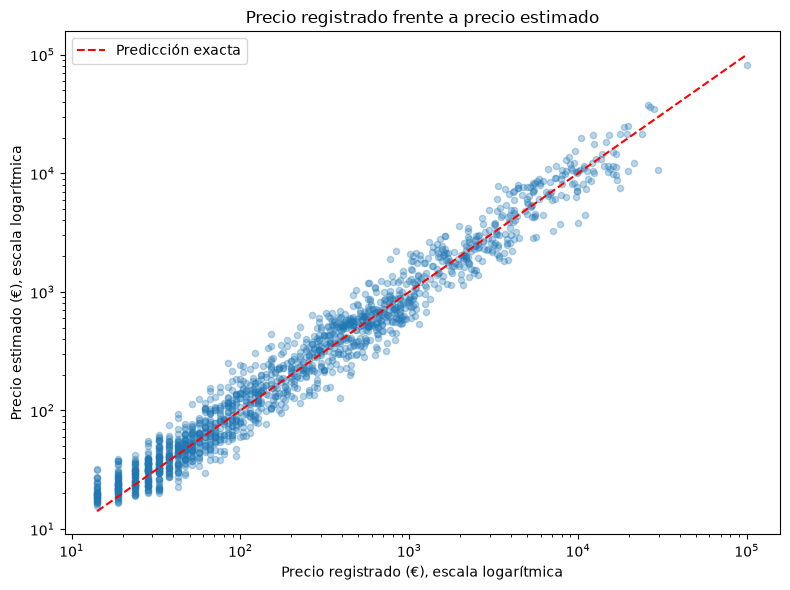

In [128]:
errores_test.plot(
    kind="scatter",
    x="Precio registrado (€)",
    y="Precio estimado (€)",
    figsize=(8, 6),
    alpha=0.3,
    logx=True,
    logy=True
)

limite_inferior = errores_test[[
    "Precio registrado (€)",
    "Precio estimado (€)"
]].min().min()

limite_superior = errores_test[[
    "Precio registrado (€)",
    "Precio estimado (€)"
]].max().max()

plt.plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    color="red",
    linestyle="--",
    label="Predicción exacta"
)

plt.title("Precio registrado frente a precio estimado")
plt.xlabel("Precio registrado (€), escala logarítmica")
plt.ylabel("Precio estimado (€), escala logarítmica")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Guardado de los datos y del modelo

Se exportan los perfiles preparados a `data/processed/instagram_preparado.csv`
para reutilizarlos en el proyecto. También se guarda el modelo en
`modelos/bagging_creatorroi.joblib`, junto con el escalador, sus columnas,
sus categorías y las versiones registradas del entorno.

Estos elementos se utilizan juntos para que Streamlit prepare cada perfil
de la misma manera que durante el entrenamiento.

El modelo guardado es el que se ha evaluado, sin volver a ajustarlo con prueba.
La comprobación carga el archivo y verifica que reproduce las predicciones,
tanto para el conjunto de prueba como para un perfil aislado.
Solo deben cargarse archivos de modelo de confianza.

**Esta celda sobrescribe los archivos indicados si ya existen.**

In [129]:
Path("data/processed").mkdir(parents=True, exist_ok=True)
instagram.to_csv("data/processed/instagram_preparado.csv", index=False)
paquete_modelo = {
    "modelo": modelo_final,
    "scaler": scaler,
    "variables": X_train.columns.tolist(),
    "columnas": columnas_modelo,
    "categorias": categorias,
    "target": "Price_Per_Reel_EUR",
    "inr_por_euro": inr_por_euro,
    "random_state": 42,
    "version_sklearn": sklearn.__version__,
    "version_pandas": pd.__version__,
    "version_numpy": np.__version__,
}
guardar_modelo(paquete_modelo, "modelos/bagging_creatorroi.joblib")
modelo_cargado = joblib.load("modelos/bagging_creatorroi.joblib")
predicciones_cargadas = predecir_tarifas(X_test, modelo_cargado)
assert np.allclose(predicciones_test, predicciones_cargadas)
# También debe funcionar un perfil aislado, como en la aplicación.
assert np.allclose(
    predecir_tarifas(X_test.iloc[[0]], modelo_cargado),
    predicciones_test[:1]
)
print("Datos y modelo guardados. Predicciones comprobadas.")


Datos y modelo guardados. Predicciones comprobadas.


## 10. Comprobación de las variables para Streamlit

Se abre el paquete guardado y se consultan sus variables de entrada y sus
campos categóricos. Esta comprobación se añadió durante la integración del
estimador para preparar el formulario con los mismos campos que el modelo.

Se esperan 11 variables, de las cuales Category, City y Language son categóricas.
Esta celda no vuelve a entrenar el modelo ni evalúa su precisión.

In [131]:
import joblib

paquete_modelo = joblib.load("modelos/bagging_creatorroi.joblib")

print("Variables del modelo:")
print(paquete_modelo["variables"])

print("\nCampos categóricos:")
print(list(paquete_modelo["categorias"]))

Variables del modelo:
['Category', 'City', 'Language', 'Followers', 'Average_Likes', 'Average_Comments', 'Average_Shares', 'Average_Saves', 'Number_of_Posts_Analyzed', 'Average_Views_Per_Content', 'Engagement_Rate_Percent']

Campos categóricos:
['Category', 'City', 'Language']


## 11. Conclusiones y próximos pasos

### Principales resultados

Se han analizado 7.800 perfiles de Instagram del mercado indio.
Los seguidores presentan una relación positiva fuerte con las tarifas,
aunque perfiles con audiencias similares pueden tener precios diferentes.

También se observan diferencias entre categorías y ciudades.
Estas comparaciones no permiten atribuir el precio a un único factor.

### Modelo seleccionado

Bagging ajustado obtuvo el menor MAE de validación entre las
configuraciones probadas.

En el conjunto de prueba obtuvo:
- MAE: 364,19 €.
- Error absoluto mediano: 33,97 €.
- Error porcentual mediano: 22,23 %.

El MAE se redujo aproximadamente un 70,5 % respecto a la referencia
que predecía siempre la mediana del entrenamiento.

### Utilidad para una agencia

El análisis puede facilitar la comparación de perfiles por categoría,
audiencia y tarifa. El modelo aporta una estimación inicial como apoyo
a la preparación de presupuestos y negociaciones.

### Limitaciones

La estimación no determina un precio correcto ni garantiza una tarifa
de contratación. El dataset no recoge factores como la calidad del
contenido, la notoriedad, las características de la audiencia o
los derechos de uso incluidos en una colaboración.

Los resultados corresponden al dataset analizado. La conversión a euros
no transforma las tarifas en precios del mercado europeo.

No se dispone de ventas ni ingresos de campañas, por lo que no se
puede calcular el retorno de la inversión.

### Integración en SEÑAL

La aplicación reúne el análisis del catálogo, la comparación de candidatos,
el cálculo del presupuesto y el estimador. La estimación orienta la negociación;
no mide el retorno económico de una campaña.

### Próximos pasos

- Publicar la aplicación y recoger comentarios de usuarios.
- Ampliar el catálogo con datos recientes y de otros mercados.
- Completar el análisis del error por categoría y tramo de tarifa del modelo final.
- Incorporar conversiones e ingresos atribuibles de campañas reales.

Estas mejoras son propuestas futuras, no funcionalidades ya implementadas.
